# Spatial patterns and the rating-popularity relationship of tourist destinations in Bali

This notebook implements the analysis plan in `PROJECT_SCOPE.md`, `REQUIREMENTS.md`, and `METHODOLOGY.md`. It audits the supplied CSV, flags data-quality issues without silently deleting records, describes destination records by category and region, estimates the association between Google ratings and rating counts, maps valid coordinates, and runs a conditional global Moran's I sensitivity analysis.

**Interpretation limits.** `jumlah_rating` is an online rating count, not visitor volume. `rating` is an observed platform score. The data are cross-sectional. Maps are descriptive. Results describe the supplied records, not every destination in Bali, and no causal or temporal claims are made.

**Running in Colab.** The notebook uses relative paths by default. If the project folder or CSV is elsewhere, set `BALI_PROJECT_ROOT` and `BALI_INPUT_CSV` before the first code cell. In Colab, upload the project folder or clone it, then set the two environment variables.

## 0. Setup

In [1]:
from __future__ import annotations

import hashlib
import os
import platform
import sys
from datetime import datetime, timezone
from pathlib import Path

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" and (cwd.parent / "src").exists() else cwd
os.environ.setdefault("BALI_PROJECT_ROOT", str(project_root))
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import display
from scipy import stats

from src import config
from src import geospatial as gs
from src import statistics as st
from src import visualizations as viz
from src.cleaning import clean_dataset
from src.data_validation import check_schema, duplicate_tables, load_dataset, missingness_table
from src.reporting import write_report

config.ensure_directories()
viz.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 150)
pd.set_option("display.max_colwidth", 90)
np.random.seed(config.RANDOM_SEED)

input_csv = Path(os.environ.get("BALI_INPUT_CSV", config.DEFAULT_INPUT_CSV))

print(f"Project root: {config.PROJECT_ROOT}")
print(f"Input CSV:    {input_csv}")
print(f"Python:       {platform.python_version()}")
print(f"pandas:       {pd.__version__}")
print(f"NumPy:        {np.__version__}")
print(f"SciPy:        {scipy.__version__}")

Project root: /home/dhanu/Downloads/bali_tourism_geospatial_project_docs/bali_tourism_geospatial_project
Input CSV:    /home/dhanu/Downloads/bali_tourism_geospatial_project_docs/bali_tourism_geospatial_project/data/raw/bali_tourist_destination.csv
Python:       3.14.8
pandas:       3.1.0
NumPy:        2.5.4
SciPy:        1.18.1


## 1. Data audit

The source file is read as text and checked against the documented schema before any numeric conversion. This preserves the raw representation of every value and avoids silent coercion.

In [2]:
raw = load_dataset(input_csv)
file_hash = hashlib.sha256(input_csv.read_bytes()).hexdigest()
schema = check_schema(raw)

schema_table = schema["audit"]
schema_table.to_csv(config.TABLE_DIR / "schema_audit.csv", index=False)

audit_summary = pd.DataFrame(
    [
        {"item": "source_rows", "value": len(raw)},
        {"item": "source_columns", "value": raw.shape[1]},
        {"item": "expected_columns_present", "value": len(config.EXPECTED_COLUMNS) - len(schema["missing_columns"])},
        {"item": "unexpected_columns", "value": len(schema["unexpected_columns"])},
        {"item": "sha256", "value": file_hash},
    ]
)
audit_summary.to_csv(config.TABLE_DIR / "dataset_audit_summary.csv", index=False)

print(f"Rows: {len(raw):,}; columns: {raw.shape[1]}")
print(f"SHA-256: {file_hash}")
if schema["missing_columns"]:
    print(f"WARNING: expected columns absent: {schema['missing_columns']}")
else:
    print("All expected columns are present.")
if schema["unexpected_columns"]:
    print(f"WARNING: unexpected columns present: {schema['unexpected_columns']}")
display(schema_table)

Rows: 1,452; columns: 11
SHA-256: 68f4ae5a8cb5f90ebf5f11c8263a8b33c2a425c85df66c936050e28e9cb4237d
All expected columns are present.


,column,expected,non_null,missing,unique_values,example_value
0,id_tempat,True,1452,0,1452,BL0101001
1,nama_tempat_wisata,True,1452,0,1437,Patung Titi Banda
2,kategori,True,1452,0,4,Umum
3,kecamatan,True,1452,0,56,Denpasar Barat
4,kabupaten_kota,True,1452,0,9,Kota Denpasar
5,rating,True,1452,0,23,4.6
6,jumlah_rating,True,1452,0,671,1941
7,latitude,True,1452,0,1439,-8.6492916
8,longitude,True,1452,0,1440,115.2550434
9,link_google_maps,True,1452,0,1452,https://www.google.com/maps/place/Patung+Titi+Banda/data=!4m7!3m6!1s0x2dd24075cfb1c9ab...


In [3]:
missing = missingness_table(raw)
missing.to_csv(config.TABLE_DIR / "missingness.csv", index=False)
display(missing)

,column,missing,non_missing,percent_missing
0,link_gambar,4,1448,0.28
1,id_tempat,0,1452,0.00
2,jumlah_rating,0,1452,0.00
3,kabupaten_kota,0,1452,0.00
4,kategori,0,1452,0.00
5,kecamatan,0,1452,0.00
6,latitude,0,1452,0.00
7,link_google_maps,0,1452,0.00
8,longitude,0,1452,0.00
9,nama_tempat_wisata,0,1452,0.00


In [4]:
duplicates = duplicate_tables(raw)
duplicate_summary = pd.DataFrame(
    [
        {"item": "exact_duplicate_rows", "value": duplicates["exact_duplicate_rows"]},
        {"item": "repeated_ids_after_first", "value": duplicates["repeated_ids"]},
        {"item": "repeated_names_after_first", "value": duplicates["repeated_names"]},
        {"item": "rows_in_name_groups", "value": len(duplicates["name_candidates"])},
        {"item": "rows_sharing_coordinates", "value": len(duplicates["coordinate_groups"])},
    ]
)
duplicate_summary.to_csv(config.TABLE_DIR / "duplicate_summary.csv", index=False)
duplicates["name_candidates"].to_csv(config.PROCESSED_DATA_DIR / "name_duplicate_candidates.csv", index=False)
duplicates["coordinate_groups"].to_csv(config.PROCESSED_DATA_DIR / "coincident_coordinate_records.csv", index=False)

display(duplicate_summary)
display(duplicates["name_candidates"].head(12))

,item,value
0,exact_duplicate_rows,0
1,repeated_ids_after_first,0
2,repeated_names_after_first,15
3,rows_in_name_groups,34
4,rows_sharing_coordinates,24


,id_tempat,nama_tempat_wisata,kategori,kecamatan,kabupaten_kota,rating,jumlah_rating,latitude,longitude,link_google_maps,link_gambar,nama_tempat_norm
0,BL0303041,Hutan Bambu,Alam,Payangan,Kabupaten Gianyar,5.0,4,-8.3836067,115.2686379,https://www.google.com/maps/place/Hutan+Bambu/data=!4m7!3m6!1s0x2dd2210cf870b483:0x899...,https://streetviewpixels-pa.googleapis.com/v1/thumbnail?panoid=NZDxUDuGwAaRGKuGavu2LQ&...,hutan bambu
1,BL0410002,Hutan Bambu,Alam,Tabanan,Kabupaten Tabanan,3.5,4,-8.3520992,115.1617287,https://www.google.com/maps/place/Hutan+Bambu/data=!4m7!3m6!1s0x2dd227dbbee56529:0x153...,https://streetviewpixels-pa.googleapis.com/v1/thumbnail?panoid=VbdB79J-QVmKJ1ibAQrxYA&...,hutan bambu
2,BL0802018,Pantai Candidasa,Alam,Bebandem,Kabupaten Karangasem,4.5,52,-8.5143733,115.5795146,https://www.google.com/maps/place/Pantai+Candidasa/data=!4m7!3m6!1s0x2dd20f285b3b290b:...,https://lh3.googleusercontent.com/p/AF1QipOlpU9nxTYGGOvOi1rJ-J1Pw-po70T-dbzoRkzb=w1080...,pantai candidasa
3,BL0805004,Pantai Candidasa,Alam,Manggis,Kabupaten Karangasem,4.4,737,-8.5086293,115.5644784,https://www.google.com/maps/place/Pantai+Candidasa/data=!4m7!3m6!1s0x2dd20ed413eea0ad:...,https://lh3.googleusercontent.com/gps-cs-s/AHVAweqib1pzk4OU6qdWPpAn-ucdGK6_NayD8YHbqZl...,pantai candidasa
4,BL0202044,Pantai Jimbaran,Alam,Kuta,Kabupaten Badung,4.7,208,-8.7813653,115.1634319,https://www.google.com/maps/place/Pantai+Jimbaran/data=!4m7!3m6!1s0x2dd245788662f3c3:0...,https://lh3.googleusercontent.com/gps-cs-s/AHVAweqKc8JhyFqaSQCpolI1UtjQIvIhcsw5jiFVvS5...,pantai jimbaran
5,BL0203006,Pantai Jimbaran,Alam,Kuta Selatan,Kabupaten Badung,3.0,2,-8.7717508,115.1708395,https://www.google.com/maps/place/Pantai+Jimbaran/data=!4m7!3m6!1s0x2dd245aceee09665:0...,https://lh3.googleusercontent.com/gps-cs-s/AHVAweqRNjax9vGBh_qlJGpjdQAXcOmTzlXqn5KRaPd...,pantai jimbaran
6,BL0202050,Pantai Kuta,Alam,Kuta,Kabupaten Badung,4.5,42383,-8.7184926,115.1686322,https://www.google.com/maps/place/Pantai+Kuta/data=!4m7!3m6!1s0x2dd246bc2ab70d43:0x82f...,https://lh3.googleusercontent.com/gps-cs-s/AHVAweqoO3_GtCs2IrCnFjE5JNJ6LriEN3LXb4NoLDX...,pantai kuta
7,BL0404017,pantai kuta,Alam,Marga,Kabupaten Tabanan,5.0,2,-8.4095178,115.188916,https://www.google.com/maps/place/pantai+kuta/data=!4m7!3m6!1s0x2dd2236ff8c827e5:0x671...,https://lh3.googleusercontent.com/gps-cs-s/AHVAwerXTIF7j6bW2nyqnN5bX6vxoHyb5ki21sck1vr...,pantai kuta
8,BL0901019,Pantai Medewi,Alam,Jembrana,Kabupaten Jembrana,4.5,4,-8.4198265,114.8052097,https://www.google.com/maps/place/Pantai+Medewi/data=!4m7!3m6!1s0x2dd3d7d7235d61ed:0xe...,https://lh3.googleusercontent.com/gps-cs-s/AHVAwerOaV_mBXksya-NIRlO3xWOSbgFM7NZx3xI1lZ...,pantai medewi
9,BL0903005,Pantai Medewi,Alam,Mendoyo,Kabupaten Jembrana,4.5,709,-8.4198265,114.8052097,https://www.google.com/maps/place/Pantai+Medewi/data=!4m7!3m6!1s0x2dd3d6a1371926d5:0xe...,https://lh3.googleusercontent.com/gps-cs-s/AHVAwerMWryw86in_iOYJCQtQleF0hJZ_fMKpkbwxzH...,pantai medewi


## 2. Transparent cleaning and flags

Cleaning adds flags and derived fields. It does not drop source records. Zero ratings are treated as unrated records, coordinates outside a broad Bali bounding box are excluded only from mapping and spatial analysis, and repeated names are retained because names alone are not proof of duplication.

In [5]:
clean_result = clean_dataset(raw)
data = clean_result.data

clean_result.cleaning_log.to_csv(config.TABLE_DIR / "cleaning_log.csv", index=False)
clean_result.name_duplicate_candidates.to_csv(config.PROCESSED_DATA_DIR / "name_duplicate_candidates.csv", index=False)
clean_result.coincident_coordinate_groups.to_csv(config.PROCESSED_DATA_DIR / "coincident_coordinate_records.csv", index=False)
clean_result.likely_duplicate_records.to_csv(config.PROCESSED_DATA_DIR / "likely_duplicate_records.csv", index=False)
clean_result.invalid_numeric_records.to_csv(config.PROCESSED_DATA_DIR / "invalid_numeric_records.csv", index=False)

coord_flagged = data[data["flag_coord_global_invalid"] | data["flag_coord_outside_bali_bbox"]].copy()
coord_flagged.to_csv(config.PROCESSED_DATA_DIR / "flagged_coordinate_records.csv", index=False)
data.to_csv(config.PROCESSED_DATA_DIR / "analysis_ready.csv", index=False)

display(clean_result.cleaning_log)
display(clean_result.likely_duplicate_records[["id_tempat", "nama_tempat_wisata", "latitude", "longitude", "rating", "jumlah_rating"]])

,step,rule,rows_flagged,rows_excluded,note
0,Audit,Rows in source file,1452,0,Raw file is preserved unchanged.
1,Cleaning,Leading or trailing whitespace trimmed in text fields,0,0,Only surrounding whitespace was removed.
2,Cleaning,Numeric fields that could not be parsed,0,0,Unparseable values are retained in the audit output.
3,Flagging,Rating recorded as zero,15,15,"A zero is treated as an unrated record, not as a literal quality score."
4,Flagging,Rating outside 0 to 5,0,0,
5,Flagging,Missing rating,0,0,
6,Flagging,Missing rating count,0,0,
7,Flagging,Negative rating count,0,0,
8,Flagging,Fractional rating count,0,0,
9,Flagging,Rating count recorded as zero,15,0,Retained in the data but excluded from the rating-count association.


,id_tempat,nama_tempat_wisata,latitude,longitude,rating,jumlah_rating
347,BL0206011,Secret Garden Village,-8.372630,115.193382,4.6,5490
378,BL0206042,Secret Garden Village,-8.372630,115.193382,4.6,5490
1323,BL0808006,Taman Asta Gangga,-8.493884,115.417700,4.7,117
1326,BL0808009,Taman Asta Gangga,-8.493884,115.417700,4.7,117


In [6]:
coordinate_review = pd.DataFrame(
    [
        {"check": "rows with complete coordinates", "value": int(data[["latitude", "longitude"]].notna().all(axis=1).sum())},
        {"check": "unique coordinate pairs", "value": int(data[["latitude", "longitude"]].drop_duplicates().shape[0])},
        {"check": "rows sharing a coordinate with another record", "value": int(data["flag_coincident_coords"].sum())},
        {"check": "coordinates inside the broad Bali bounding box", "value": int(data["coords_in_bali"].sum())},
        {"check": "coordinates outside the broad Bali bounding box", "value": int(data["flag_coord_outside_bali_bbox"].sum())},
        {"check": "coordinates invalid at global scale", "value": int(data["flag_coord_global_invalid"].sum())},
        {"check": "bounding box latitude", "value": f"{config.BALI_BBOX['lat_min']} to {config.BALI_BBOX['lat_max']}"},
        {"check": "bounding box longitude", "value": f"{config.BALI_BBOX['lon_min']} to {config.BALI_BBOX['lon_max']}"},
    ]
)
coordinate_review.to_csv(config.TABLE_DIR / "coordinate_review.csv", index=False)
display(coordinate_review)
display(coord_flagged[["id_tempat", "nama_tempat_wisata", "kecamatan", "kabupaten_kota", "latitude", "longitude"]])

,check,value
0,rows with complete coordinates,1452
1,unique coordinate pairs,1440
2,rows sharing a coordinate with another record,24
3,coordinates inside the broad Bali bounding box,1445
4,coordinates outside the broad Bali bounding box,7
5,coordinates invalid at global scale,0
6,bounding box latitude,-9.3 to -7.7
7,bounding box longitude,114.3 to 115.9


,id_tempat,nama_tempat_wisata,kecamatan,kabupaten_kota,latitude,longitude
661,BL0402001,Goa Selomangleng,Kediri,Kabupaten Tabanan,-7.807188,111.972672
670,BL0402010,Taman Wisata Tirtoyoso Park,Kediri,Kabupaten Tabanan,-7.816438,112.029748
673,BL0402013,Air Terjun Dolo,Kediri,Kabupaten Tabanan,-7.867689,111.833469
678,BL0402018,Gumul Paradise Island,Kediri,Kabupaten Tabanan,-7.811681,112.061169
682,BL0402022,Taman Hutan Joyoboyo Kediri,Kediri,Kabupaten Tabanan,-7.818138,112.029716
684,BL0402024,Wisata Sempu Exotic Park,Kediri,Kabupaten Tabanan,-7.960526,112.217889
688,BL0402028,Air Terjun Irenggolo,Kediri,Kabupaten Tabanan,-7.863541,111.850352


The seven flagged records carry Tabanan labels but coordinates that fall around Kediri, East Java, rather than in Bali. They are retained in the processed file and excluded only from geographic analyses. The broad box is a screening aid, not an administrative boundary.

## 3. Descriptive analysis

Counts use all source records. Rating summaries use records with a rating above zero and at most 5. The rating-count association uses records with a rating above zero and a positive whole-number rating count.

In [7]:
category_counts = data["kategori"].value_counts().reindex(config.CATEGORY_ORDER, fill_value=0)
category_table = category_counts.rename_axis("kategori").reset_index(name="records")
category_table.to_csv(config.TABLE_DIR / "category_counts.csv", index=False)

regency_counts = data["kabupaten_kota"].value_counts()
regency_table = regency_counts.rename_axis("kabupaten_kota").reset_index(name="records")
regency_table.to_csv(config.TABLE_DIR / "regency_counts.csv", index=False)

subdistrict_counts = data["kecamatan"].value_counts()
subdistrict_table = subdistrict_counts.rename_axis("kecamatan").reset_index(name="records")
subdistrict_table.to_csv(config.TABLE_DIR / "subdistrict_counts.csv", index=False)

geo_data = data[data["analytic_geo"]].copy()
category_counts_geo = geo_data["kategori"].value_counts().reindex(config.CATEGORY_ORDER, fill_value=0)
category_table_geo = category_counts_geo.rename_axis("kategori").reset_index(name="records")
category_table_geo.to_csv(config.TABLE_DIR / "category_counts_valid_coordinates.csv", index=False)

regency_counts_geo = geo_data["kabupaten_kota"].value_counts()
regency_table_geo = regency_counts_geo.rename_axis("kabupaten_kota").reset_index(name="records")
regency_table_geo.to_csv(config.TABLE_DIR / "regency_counts_valid_coordinates.csv", index=False)

subdistrict_counts_geo = geo_data["kecamatan"].value_counts()
subdistrict_table_geo = subdistrict_counts_geo.rename_axis("kecamatan").reset_index(name="records")
subdistrict_table_geo.to_csv(config.TABLE_DIR / "subdistrict_counts_valid_coordinates.csv", index=False)

regency_comparison = regency_table.merge(
    regency_table_geo, on="kabupaten_kota", how="outer", suffixes=("_all", "_valid_coordinates")
).fillna(0)
regency_comparison[["records_all", "records_valid_coordinates"]] = regency_comparison[
    ["records_all", "records_valid_coordinates"]
].astype(int)
regency_comparison.to_csv(config.TABLE_DIR / "regency_counts_comparison.csv", index=False)

display(category_table)
display(regency_comparison)
display(subdistrict_table.head(15))

,kategori,records
0,Alam,529
1,Budaya,182
2,Rekreasi,164
3,Umum,577


,kabupaten_kota,records_all,records_valid_coordinates
0,Kabupaten Badung,261,261
1,Kabupaten Bangli,110,110
2,Kabupaten Buleleng,169,169
3,Kabupaten Gianyar,215,215
4,Kabupaten Jembrana,103,103
5,Kabupaten Karangasem,158,158
6,Kabupaten Klungkung,136,136
7,Kabupaten Tabanan,170,163
8,Kota Denpasar,130,130


,kecamatan,records
0,Abiansemal,71
1,Kintamani,66
2,Nusa Penida,64
3,Blahbatuh,62
4,Denpasar Barat,61
5,Jembrana,60
6,Kuta,58
7,Baturiti,55
8,Banjarangkan,55
9,Petang,54


In [8]:
main = data[data["analytic_popularity"]].copy()
rating_sample = data[data["analytic_rating"]].copy()

rating_summary = st.describe_series(rating_sample["rating"], "Google rating")
count_summary = st.describe_series(main["jumlah_rating"], "Number of Google ratings")
log_count_summary = st.describe_series(np.log1p(main["jumlah_rating"]), "log1p(number of Google ratings)")

summary_table = pd.DataFrame([rating_summary, count_summary, log_count_summary])
summary_table.to_csv(config.TABLE_DIR / "descriptive_summary.csv", index=False)
display(summary_table)

rating_by_category = st.group_summary(rating_sample, "kategori", "rating")
count_by_category = st.group_summary(main, "kategori", "jumlah_rating")
rating_by_regency = st.group_summary(rating_sample, "kabupaten_kota", "rating")
count_by_regency = st.group_summary(main, "kabupaten_kota", "jumlah_rating")

rating_by_category.to_csv(config.TABLE_DIR / "rating_by_category.csv", index=False)
count_by_category.to_csv(config.TABLE_DIR / "rating_count_by_category.csv", index=False)
rating_by_regency.to_csv(config.TABLE_DIR / "rating_by_regency.csv", index=False)
count_by_regency.to_csv(config.TABLE_DIR / "rating_count_by_regency.csv", index=False)

display(rating_by_category)
display(count_by_category)

,variable,n,missing,mean,sd,median,q1,q3,iqr,min,max,skewness
0,Google rating,1437,0,4.552053,0.322299,4.600000,4.400000,4.800000,0.400000,2.000000,5.000000,-1.568497
1,Number of Google ratings,1437,0,1188.454419,5294.611077,112.000000,25.000000,477.000000,452.000000,1.000000,101523.000000,10.538194
2,log1p(number of Google ratings),1437,0,4.795114,2.080337,4.727388,3.258097,6.169611,2.911514,0.693147,11.528051,0.301081


,group,n,mean,sd,median,q1,q3,iqr,min,max
0,Umum,565,4.568142,0.354021,4.6,4.4,4.8,0.4,3.0,5.0
1,Alam,528,4.521591,0.320797,4.5,4.4,4.7,0.3,2.0,5.0
2,Budaya,182,4.635165,0.206456,4.7,4.5,4.8,0.3,3.7,5.0
3,Rekreasi,162,4.501852,0.297291,4.5,4.4,4.7,0.3,3.5,5.0


,group,n,mean,sd,median,q1,q3,iqr,min,max
0,Umum,565,893.592920,3876.973850,88.0,19.00,369.00,350.00,1.0,57613.0
1,Alam,528,1027.681818,4278.667952,109.0,28.75,445.50,416.75,1.0,49969.0
2,Budaya,182,1969.978022,9117.802399,155.5,39.50,553.75,514.25,1.0,101523.0
3,Rekreasi,162,1862.820988,6515.678812,167.0,37.00,1105.75,1068.75,1.0,70182.0


### 3.1 Counts and distributions

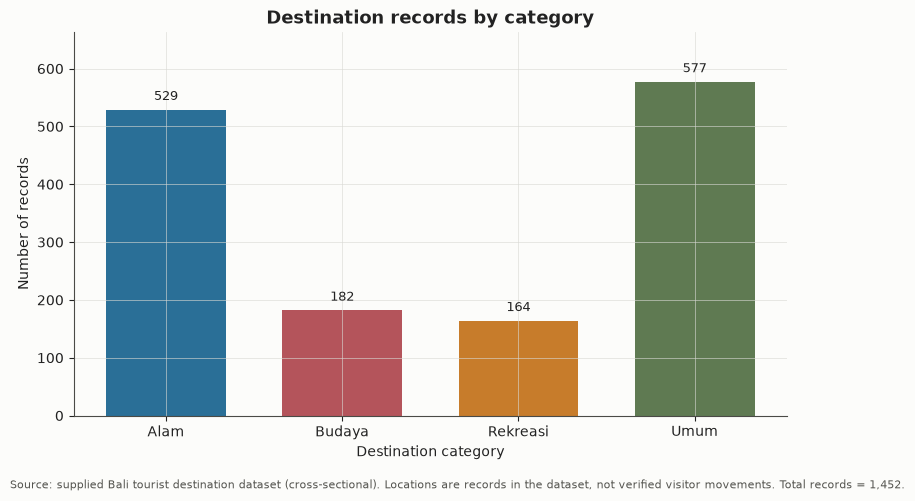

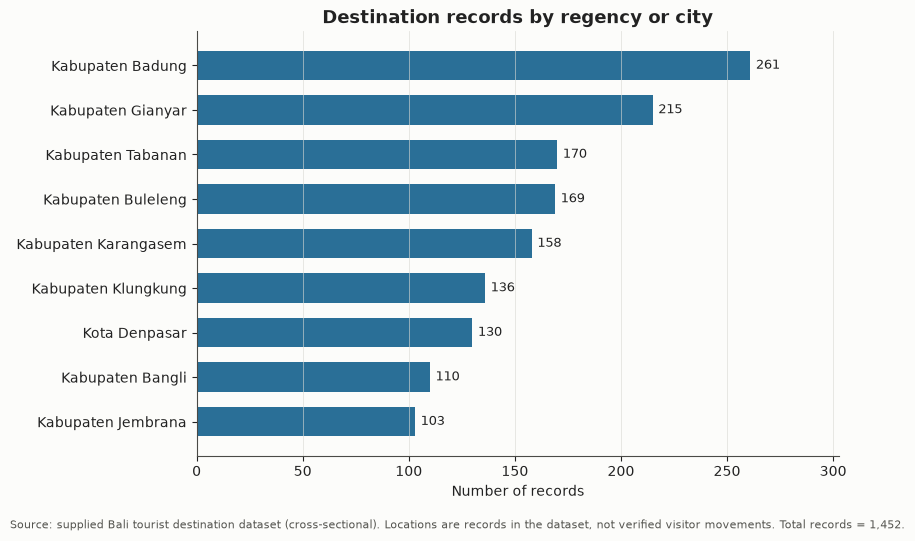

In [9]:
viz.plot_category_counts(category_counts, config.FIGURE_DIR / "01_category_counts.png")
viz.plot_regency_counts(regency_counts, config.FIGURE_DIR / "02_regency_counts.png")

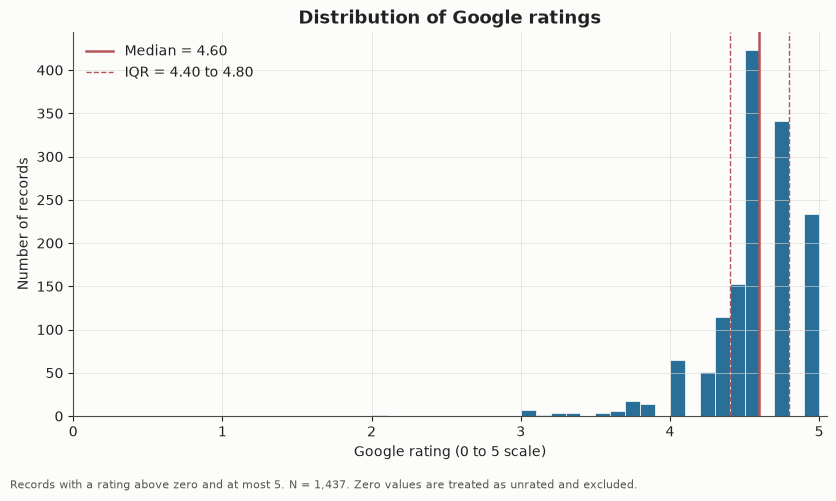

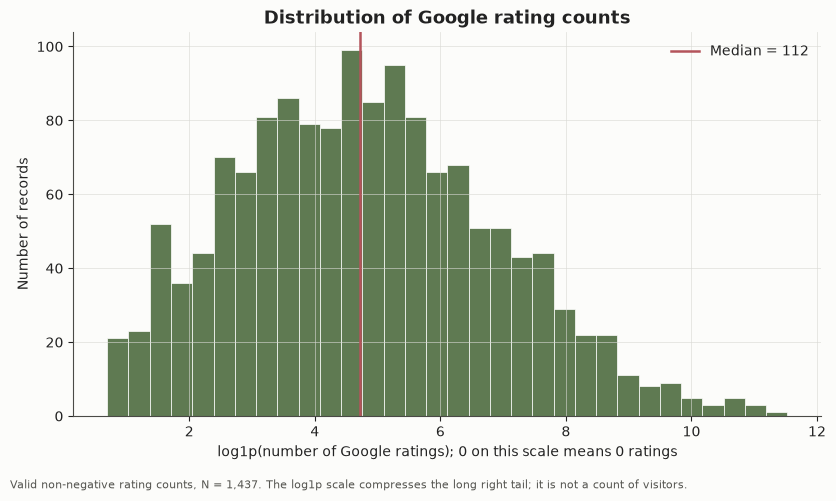

In [10]:
viz.plot_rating_distribution(rating_sample["rating"], config.FIGURE_DIR / "03_rating_distribution.png")
viz.plot_count_distribution(main["jumlah_rating"], config.FIGURE_DIR / "04_rating_count_distribution.png")

## 4. Rating-popularity association

The primary estimate is Spearman's rank correlation. Ratings are rounded to one decimal place, so ties are expected and the rank measure is appropriate. The confidence interval comes from a percentile bootstrap that resamples paired records with a fixed seed. Pearson correlations are shown only as secondary comparisons.

In [11]:
correlation = st.spearman_association(
    main,
    "rating",
    "jumlah_rating",
    n_bootstrap=config.N_BOOTSTRAP,
    seed=config.RANDOM_SEED,
)
pearson_raw = stats.pearsonr(main["rating"], main["jumlah_rating"])
pearson_log = stats.pearsonr(main["rating"], np.log1p(main["jumlah_rating"]))

correlation_table = pd.DataFrame([correlation])
correlation_table["pearson_raw_r"] = pearson_raw.statistic
correlation_table["pearson_raw_p"] = pearson_raw.pvalue
correlation_table["pearson_log_r"] = pearson_log.statistic
correlation_table["pearson_log_p"] = pearson_log.pvalue
correlation_table.to_csv(config.TABLE_DIR / "rating_popularity_association.csv", index=False)

alternatives = pd.DataFrame(
    [
        {"method": "Spearman rank", "variables": "rating versus count", "n": correlation["n"], "statistic": correlation["rho"], "p_value": correlation["p_value"]},
        {"method": "Pearson raw", "variables": "rating versus count", "n": int(len(main)), "statistic": pearson_raw.statistic, "p_value": pearson_raw.pvalue},
        {"method": "Pearson log1p count", "variables": "rating versus log1p(count)", "n": int(len(main)), "statistic": pearson_log.statistic, "p_value": pearson_log.pvalue},
    ]
)
alternatives.to_csv(config.TABLE_DIR / "rating_popularity_alternatives.csv", index=False)

display(
    correlation_table[
        ["n", "rho", "p_value", "ci_low", "ci_high", "bootstrap_replicates", "unique_x", "unique_y"]
    ]
)
display(alternatives)

,n,rho,p_value,ci_low,ci_high,bootstrap_replicates,unique_x,unique_y
0,1437,-0.218466,5.488354e-17,-0.27413,-0.1658,2000,22,670


,method,variables,n,statistic,p_value
0,Spearman rank,rating versus count,1437,-0.218466,5.488354e-17
1,Pearson raw,rating versus count,1437,-0.019648,4.567400e-01
2,Pearson log1p count,rating versus log1p(count),1437,-0.113909,1.502007e-05


In [12]:
print(
    f"Among {correlation['n']:,} records with a rating above zero and a positive rating count, "
    f"rating and rating count showed a weak negative rank association "
    f"(Spearman rho = {correlation['rho']:.3f}, 95% bootstrap CI "
    f"{correlation['ci_low']:.3f} to {correlation['ci_high']:.3f}, p = {correlation['p_value']:.2e}). "
    "This describes the supplied records only and does not show that ratings cause review engagement."
)

Among 1,437 records with a rating above zero and a positive rating count, rating and rating count showed a weak negative rank association (Spearman rho = -0.218, 95% bootstrap CI -0.274 to -0.166, p = 5.49e-17). This describes the supplied records only and does not show that ratings cause review engagement.


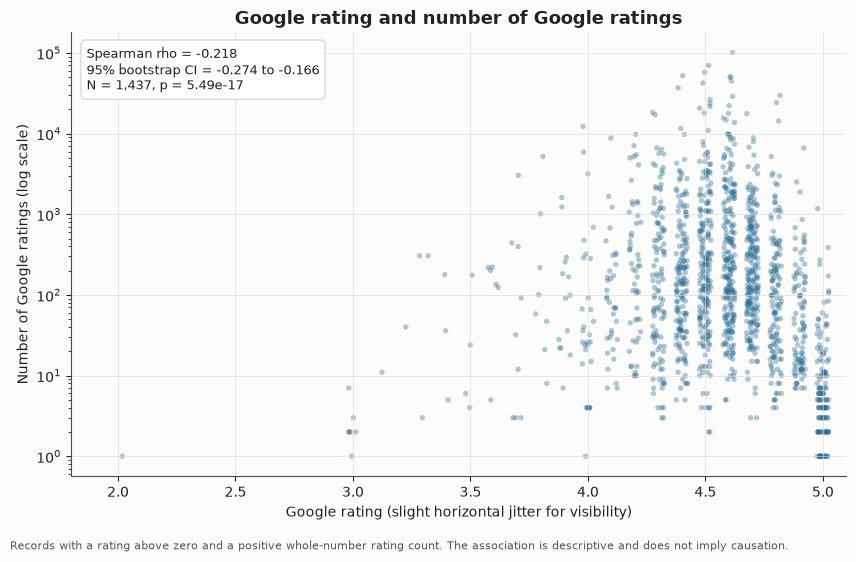

In [13]:
viz.plot_rating_vs_count(main, correlation, config.FIGURE_DIR / "05_rating_vs_count.png")

## 5. Category and regional comparisons

These are secondary analyses. Kruskal-Wallis tests compare ranks across groups. Where an overall test is significant, pairwise Dunn comparisons use a tie correction and Holm adjustment. Effect sizes are reported alongside p-values.

In [14]:
comparison_specs = [
    ("Google rating by category", rating_sample, "kategori", "rating"),
    ("Google rating by regency or city", rating_sample, "kabupaten_kota", "rating"),
    ("Rating count by category", main, "kategori", "jumlah_rating"),
    ("Rating count by regency or city", main, "kabupaten_kota", "jumlah_rating"),
]

group_test_rows = []
posthoc_frames = []
for label, frame, group_column, value_column in comparison_specs:
    result = st.kruskal_wallis(frame, group_column, value_column, min_group_n=5)
    result["label"] = label
    group_test_rows.append(result)
    posthoc = st.dunn_posthoc(frame, group_column, value_column, min_group_n=5)
    if not posthoc.empty:
        posthoc.insert(0, "analysis", label)
        posthoc_frames.append(posthoc)

group_tests_table = pd.DataFrame(group_test_rows)[
    ["label", "group", "value", "n", "groups", "statistic", "p_value", "epsilon_squared"]
]
group_tests_table.to_csv(config.TABLE_DIR / "group_comparisons.csv", index=False)

posthoc_table = pd.concat(posthoc_frames, ignore_index=True) if posthoc_frames else pd.DataFrame()
posthoc_table.to_csv(config.TABLE_DIR / "group_comparisons_posthoc.csv", index=False)

display(group_tests_table)
display(posthoc_table[posthoc_table["analysis"] == "Google rating by category"])

,label,group,value,n,groups,statistic,p_value,epsilon_squared
0,Google rating by category,kategori,rating,1437,4,32.808405,3.534737e-07,0.020801
1,Google rating by regency or city,kabupaten_kota,rating,1437,9,34.845346,2.852959e-05,0.018799
2,Rating count by category,kategori,jumlah_rating,1437,4,20.827900,1.143048e-04,0.012441
3,Rating count by regency or city,kabupaten_kota,jumlah_rating,1437,9,87.757986,1.325042e-15,0.055853


,analysis,group_a,group_b,n_a,n_b,z,p_value,p_holm,significant_holm_0_05
0,Google rating by category,Budaya,Rekreasi,182,162,4.555465,0.000005,0.000031,True
1,Google rating by category,Alam,Budaya,528,182,-4.526533,0.000006,0.000031,True
2,Google rating by category,Rekreasi,Umum,162,565,-3.443623,0.000574,0.002296,True
3,Google rating by category,Alam,Umum,528,565,-3.369006,0.000754,0.002296,True
4,Google rating by category,Budaya,Umum,182,565,2.172409,0.029825,0.059650,False
5,Google rating by category,Alam,Rekreasi,528,162,1.146552,0.251567,0.251567,False


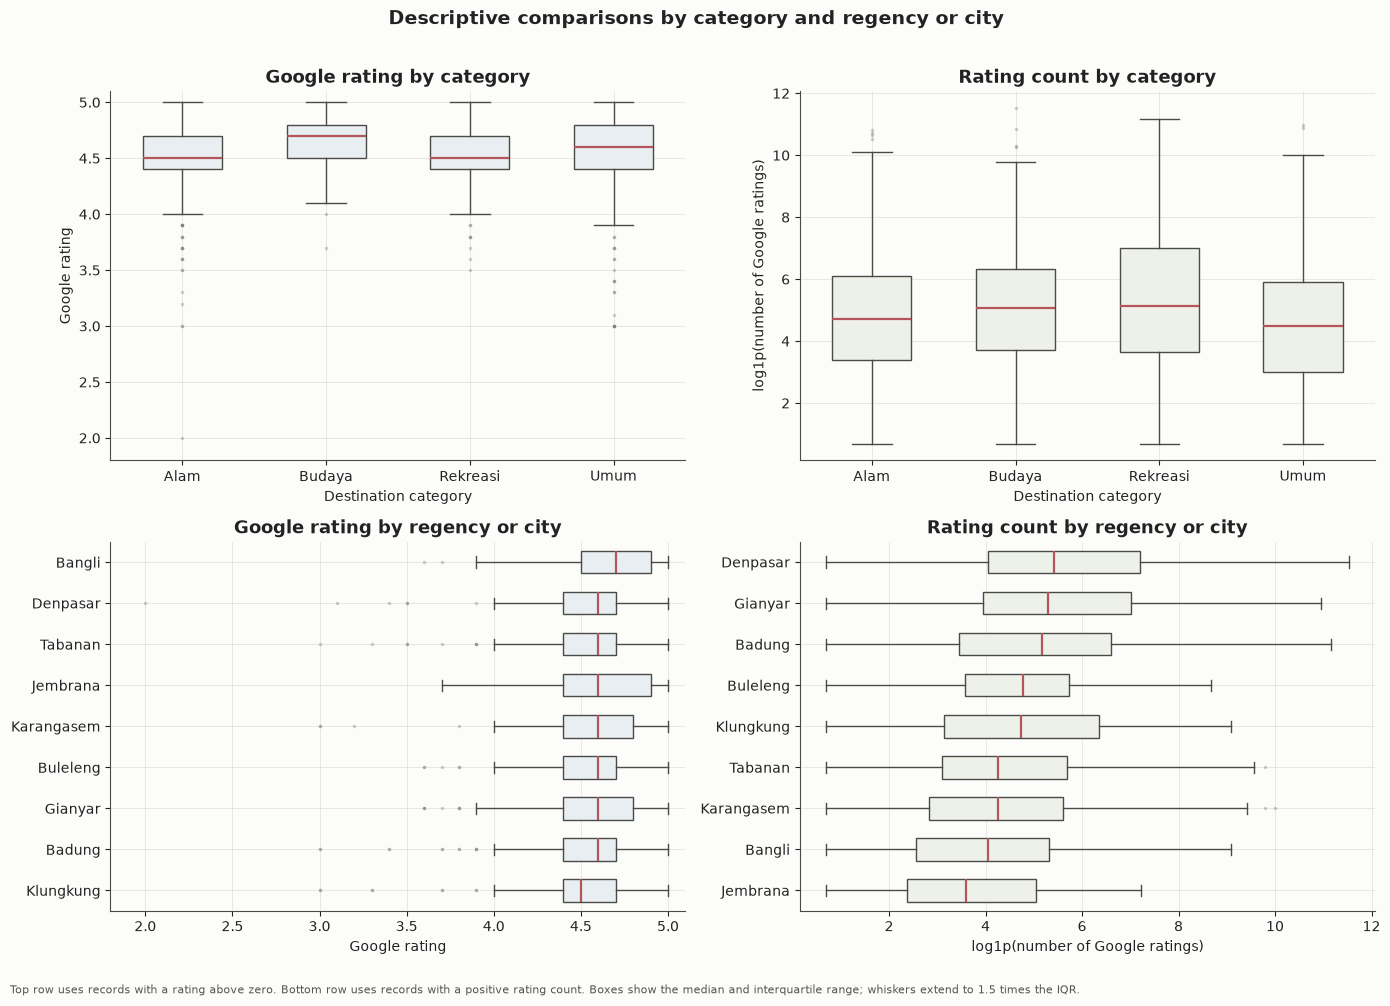

In [15]:
viz.plot_group_distributions(data, config.FIGURE_DIR / "06_group_distributions.png")

## 6. Geographic description

Maps show records with coordinates inside the broad Bali bounding box. Marker colour encodes category or the observed attribute. The scale bar is approximate and computed at the mean latitude of the map extent. The box and map extent are not official administrative boundaries.

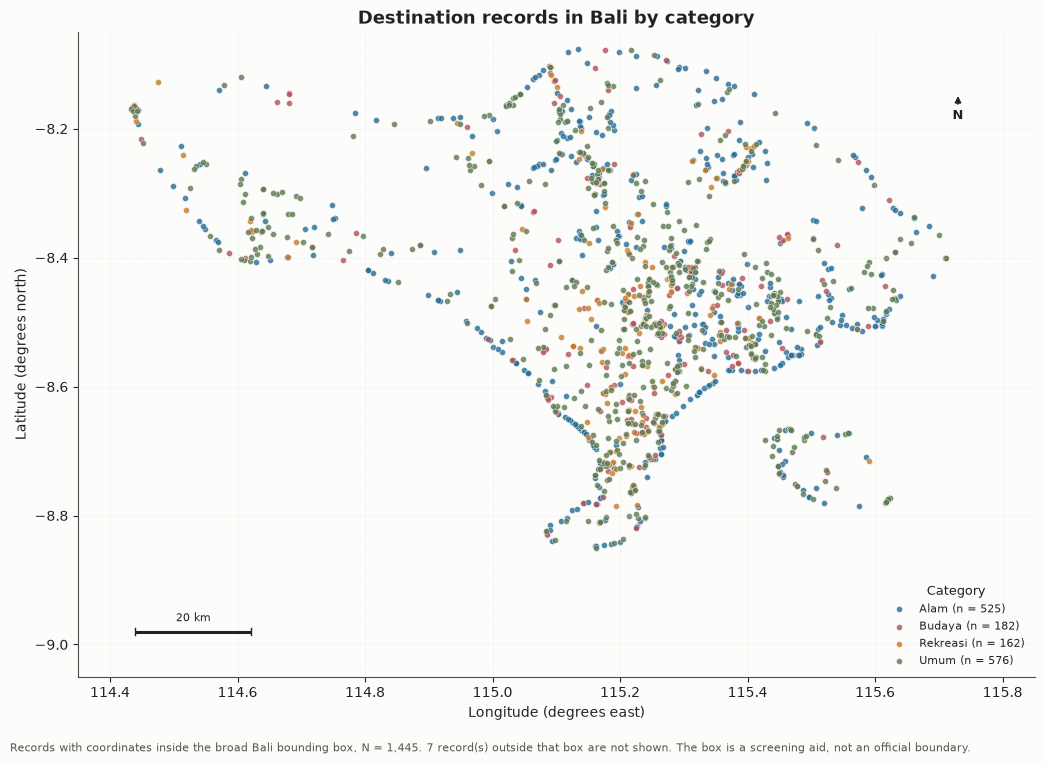

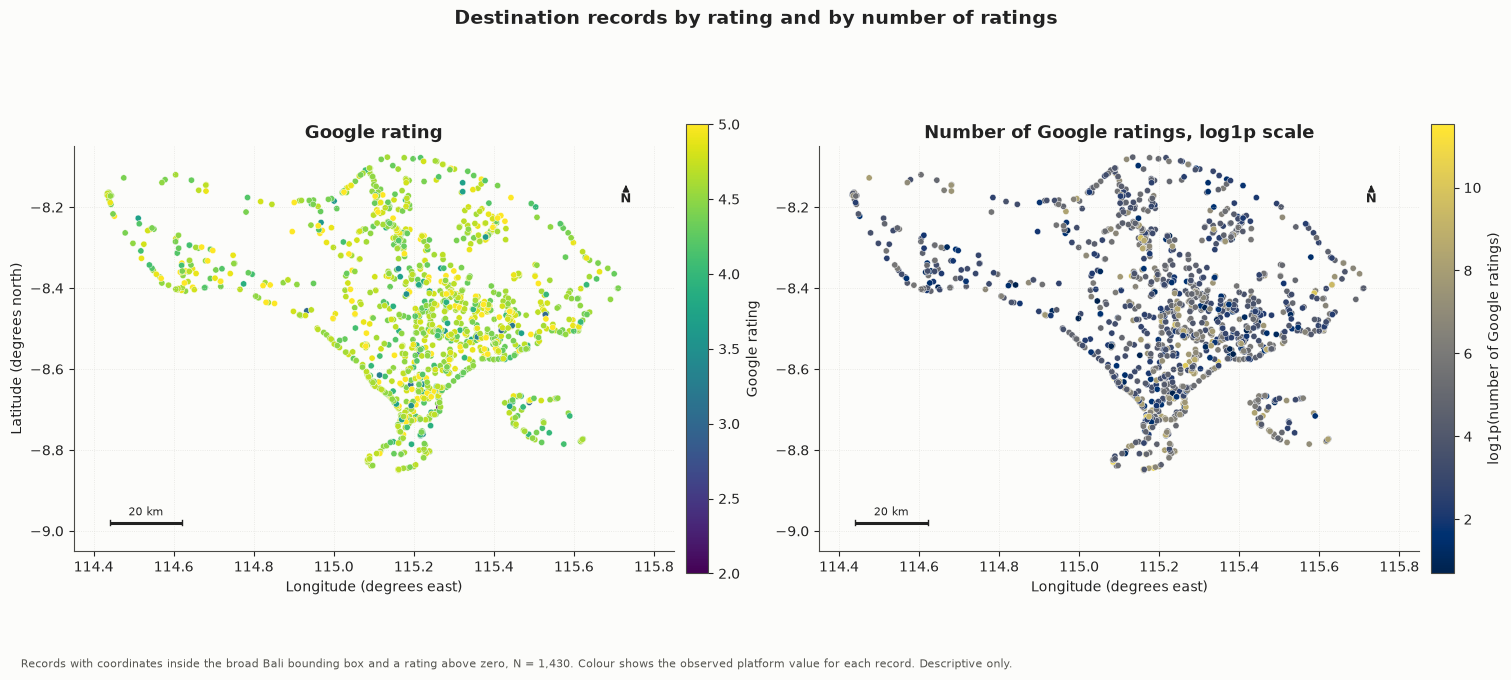

In [16]:
n_geo = int(data["analytic_geo"].sum())
n_excluded_geo = int(len(data) - n_geo)

viz.plot_point_map(data, config.FIGURE_DIR / "07_map_destinations.png", excluded=n_excluded_geo)
viz.plot_attribute_maps(data, config.FIGURE_DIR / "08_map_attributes.png")

## 7. Conditional spatial autocorrelation

Global Moran's I is run only after reviewing coordinate validity, coincident records, sample size, and the weights design. The primary weights use k = 8 nearest neighbours in UTM zone 50S metres, row-standardised. Sensitivity settings use k = 4 and k = 12. A coordinate-level aggregation and a largest-connected-component restriction are also reported. Moran's I measures global spatial autocorrelation; it is not a local hotspot analysis.

In [17]:
spatial_sample = data[data["analytic_geo"] & data["analytic_rating"]].dropna(
    subset=["rating", "log_jumlah_rating"]
).copy()
x_metres, y_metres = gs.project_coordinates(spatial_sample)
coords_metres = np.column_stack([x_metres, y_metres])
primary_weights = gs.knn_weights(coords_metres, config.PRIMARY_K)
primary_diagnostics = gs.weights_diagnostics(primary_weights)

spatial_feasibility = pd.DataFrame(
    [
        {"check": "records in spatial sample", "value": len(spatial_sample)},
        {"check": "unique coordinate pairs", "value": int(spatial_sample[["latitude", "longitude"]].drop_duplicates().shape[0])},
        {"check": "coincident records in full data", "value": int(data["flag_coincident_coords"].sum())},
        {"check": "primary k", "value": config.PRIMARY_K},
        {"check": "connected components at primary k", "value": primary_diagnostics["components"]},
        {"check": "minimum neighbours", "value": primary_diagnostics["min_neighbours"]},
        {"check": "maximum neighbours", "value": primary_diagnostics["max_neighbours"]},
        {"check": "row-standardised weights sum to one", "value": primary_diagnostics["row_sums_close_to_one"]},
    ]
)
spatial_feasibility.to_csv(config.TABLE_DIR / "spatial_feasibility.csv", index=False)
display(spatial_feasibility)

,check,value
0,records in spatial sample,1430
1,unique coordinate pairs,1419
2,coincident records in full data,24
3,primary k,8
4,connected components at primary k,2
5,minimum neighbours,8
6,maximum neighbours,8
7,row-standardised weights sum to one,True


In [18]:
spatial_frames = []
for variable in ["rating", "log_jumlah_rating"]:
    spatial_frames.append(
        gs.moran_sensitivity(
            spatial_sample,
            variable,
            ks=config.KNN_KS,
            permutations=config.N_PERMUTATIONS,
            seed=config.RANDOM_SEED,
        )
    )
spatial_results = pd.concat(spatial_frames, ignore_index=True)
spatial_results.to_csv(config.TABLE_DIR / "spatial_autocorrelation.csv", index=False)

aggregated_frames = []
for variable in ["rating", "log_jumlah_rating"]:
    aggregated = gs.aggregate_coincident_locations(spatial_sample, variable)
    aggregated_frames.append(
        gs.moran_sensitivity(
            aggregated,
            variable,
            ks=config.KNN_KS,
            permutations=config.N_PERMUTATIONS,
            seed=config.RANDOM_SEED,
        )
    )
spatial_aggregated = pd.concat(aggregated_frames, ignore_index=True)
spatial_aggregated.to_csv(config.TABLE_DIR / "spatial_autocorrelation_aggregated.csv", index=False)

display(spatial_results)
display(spatial_aggregated)

,variable,k,n,morans_i,expected_i,p_perm_greater,p_perm_two_sided,permutations,components,min_neighbours,max_neighbours
0,rating,4,1430,0.081975,-0.0007,0.001,0.001,999,6,4,4
1,rating,8,1430,0.058902,-0.0007,0.001,0.001,999,2,8,8
2,rating,12,1430,0.050186,-0.0007,0.001,0.001,999,2,12,12
3,log_jumlah_rating,4,1430,0.126361,-0.0007,0.001,0.001,999,6,4,4
4,log_jumlah_rating,8,1430,0.117850,-0.0007,0.001,0.001,999,2,8,8
5,log_jumlah_rating,12,1430,0.105328,-0.0007,0.001,0.001,999,2,12,12


,variable,k,n,morans_i,expected_i,p_perm_greater,p_perm_two_sided,permutations,components,min_neighbours,max_neighbours
0,rating,4,1419,0.079638,-0.000705,0.001,0.001,999,6,4,4
1,rating,8,1419,0.060652,-0.000705,0.001,0.001,999,2,8,8
2,rating,12,1419,0.050006,-0.000705,0.001,0.001,999,2,12,12
3,log_jumlah_rating,4,1419,0.130797,-0.000705,0.001,0.001,999,6,4,4
4,log_jumlah_rating,8,1419,0.117493,-0.000705,0.001,0.001,999,2,8,8
5,log_jumlah_rating,12,1419,0.105774,-0.000705,0.001,0.001,999,2,12,12


In [19]:
from scipy.sparse.csgraph import connected_components

_, component_labels = connected_components(primary_weights, directed=True, connection="weak")
component_sizes = pd.Series(component_labels).value_counts()
largest_label = int(component_sizes.idxmax())
component_sample = spatial_sample.iloc[component_labels == largest_label].copy()
spatial_component = gs.moran_sensitivity(
    component_sample,
    "log_jumlah_rating",
    ks=(config.PRIMARY_K,),
    permutations=config.N_PERMUTATIONS,
    seed=config.RANDOM_SEED,
)
spatial_component["component"] = "largest connected component"
spatial_component.to_csv(config.TABLE_DIR / "spatial_autocorrelation_largest_component.csv", index=False)

print(
    f"The primary weights form {primary_diagnostics['components']} connected component(s). "
    f"The largest component contains {len(component_sample):,} records; "
    f"the remaining {int(len(spatial_sample) - len(component_sample)):,} records are island or separated locations."
)
display(spatial_component)

The primary weights form 2 connected component(s). The largest component contains 1,367 records; the remaining 63 records are island or separated locations.


,variable,k,n,morans_i,expected_i,p_perm_greater,p_perm_two_sided,permutations,components,min_neighbours,max_neighbours,component
0,log_jumlah_rating,8,1367,0.118767,-0.000732,0.001,0.001,999,1,8,8,largest connected component


The k-nearest-neighbour graph does not connect the Nusa Penida and Lembongan records to the mainland at k = 8 or k = 12. The global statistic remains defined because it is computed over the full weights matrix, but the component structure limits cross-island interpretation. That is why the largest-component sensitivity is reported.

## 8. Robustness checks

The association is recomputed under alternative eligibility rules. These are descriptive sensitivity specifications, not separate hypothesis tests.

In [20]:
def add_specification(rows: list[dict], label: str, subset: pd.DataFrame) -> None:
    pairs = subset[["rating", "jumlah_rating"]].apply(pd.to_numeric, errors="coerce").dropna()
    if len(pairs) < 3:
        rows.append({"specification": label, "n": len(pairs), "rho": np.nan, "p_value": np.nan, "direction": "insufficient data"})
        return
    rho, p_value = stats.spearmanr(pairs["rating"], pairs["jumlah_rating"])
    rows.append(
        {
            "specification": label,
            "n": int(len(pairs)),
            "rho": float(rho),
            "p_value": float(p_value),
            "direction": "positive" if rho > 0 else "negative" if rho < 0 else "zero",
        }
    )


deduplicated = data.drop_duplicates(
    subset=["nama_tempat_norm", "latitude", "longitude", "rating", "jumlah_rating"]
)
deduplicated = deduplicated[deduplicated["analytic_popularity"]]

robustness_rows: list[dict] = []
add_specification(robustness_rows, "Primary: rating above 0 and positive count", main)
add_specification(robustness_rows, "Include zero ratings and zero counts as observed values", data)
add_specification(robustness_rows, "Exclude all records flagged as likely duplicates", main[~main["flag_likely_duplicate_record"]])
add_specification(robustness_rows, "Deduplicate matching records, keep first", deduplicated)
add_specification(robustness_rows, "Exclude records sharing a coordinate", main[~main["flag_coincident_coords"]])
add_specification(robustness_rows, "Restrict to records inside the Bali bounding box", main[main["analytic_geo"]])
add_specification(robustness_rows, "Restrict to ratings of 4 or above", main[main["rating"] >= 4])

robustness_table = pd.DataFrame(robustness_rows)
robustness_table.to_csv(config.TABLE_DIR / "robustness_spearman.csv", index=False)
display(robustness_table)

,specification,n,rho,p_value,direction
0,Primary: rating above 0 and positive count,1437,-0.218466,5.488354e-17,negative
1,Include zero ratings and zero counts as observed values,1452,-0.180852,3.844863e-12,negative
2,Exclude all records flagged as likely duplicates,1433,-0.218987,5.095560e-17,negative
3,"Deduplicate matching records, keep first",1435,-0.218725,5.290824e-17,negative
4,Exclude records sharing a coordinate,1414,-0.214734,3.269576e-16,negative
5,Restrict to records inside the Bali bounding box,1430,-0.216482,1.257539e-16,negative
6,Restrict to ratings of 4 or above,1380,-0.272413,6.617799e-25,negative


## 9. Reproducible outputs and report

The report below is generated from the executed objects in this notebook. It does not contain placeholder results. The raw CSV remains unchanged, and the processed table retains every source record with flags and derived fields.

In [21]:
environment_table = pd.DataFrame(
    [
        {"package": "python", "version": platform.python_version()},
        {"package": "pandas", "version": pd.__version__},
        {"package": "numpy", "version": np.__version__},
        {"package": "scipy", "version": scipy.__version__},
        {"package": "matplotlib", "version": plt.matplotlib.__version__},
        {"package": "platform", "version": platform.platform()},
    ]
)
environment_table.to_csv(config.TABLE_DIR / "environment_versions.csv", index=False)
display(environment_table)

,package,version
0,python,3.14.8
1,pandas,3.1.0
2,numpy,2.5.4
3,scipy,1.18.1
4,matplotlib,3.11.2
5,platform,Linux-7.2.11-200.fc44.x86_64-x86_64-with-glibc2.43


In [22]:
pearson_context = {"r": float(pearson_raw.statistic), "n": int(len(main))}

report_path = config.REPORT_DIR / "analysis_report.md"
report_context = {
    "generated_at": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC"),
    "input_csv": str(input_csv),
    "file_sha256": file_hash,
    "n_rows": len(raw),
    "n_columns": raw.shape[1],
    "missing_columns": schema["missing_columns"],
    "unexpected_columns": schema["unexpected_columns"],
    "exact_duplicates": duplicates["exact_duplicate_rows"],
    "repeated_ids": duplicates["repeated_ids"],
    "repeated_names": duplicates["repeated_names"],
    "name_group_rows": len(duplicates["name_candidates"]),
    "rating_zero": int(data["flag_rating_zero"].sum()),
    "coords_outside": int(data["flag_coord_outside_bali_bbox"].sum()),
    "coincident_rows": int(data["flag_coincident_coords"].sum()),
    "likely_duplicates": int(data["flag_likely_duplicate_record"].sum()),
    "missing_image_links": int(data["flag_missing_image_link"].sum()),
    "n_geo": n_geo,
    "cleaning_log": clean_result.cleaning_log,
    "category_counts": category_table,
    "regency_counts": regency_table,
    "regency_counts_geo": regency_table_geo,
    "rating_summary": rating_summary,
    "count_summary": count_summary,
    "correlation": correlation,
    "pearson": pearson_context,
    "robustness": robustness_table,
    "group_tests": group_test_rows,
    "posthoc": posthoc_table,
    "spatial": spatial_results,
    "spatial_aggregated": spatial_aggregated,
    "spatial_component": spatial_component,
}
write_report(report_context, report_path)

output_files = sorted(
    [
        str(path.relative_to(config.PROJECT_ROOT))
        for path in list(config.FIGURE_DIR.glob("*.png"))
        + list(config.TABLE_DIR.glob("*.csv"))
        + list(config.PROCESSED_DATA_DIR.glob("*.csv"))
        + [report_path]
    ]
)
report_context["outputs"] = output_files
write_report(report_context, report_path)

print(f"Report written to: {report_path}")
for path in output_files:
    print(f"  {path}")

Report written to: /home/dhanu/Downloads/bali_tourism_geospatial_project_docs/bali_tourism_geospatial_project/outputs/reports/analysis_report.md
  data/processed/analysis_ready.csv
  data/processed/coincident_coordinate_records.csv
  data/processed/flagged_coordinate_records.csv
  data/processed/invalid_numeric_records.csv
  data/processed/likely_duplicate_records.csv
  data/processed/name_duplicate_candidates.csv
  outputs/figures/01_category_counts.png
  outputs/figures/02_regency_counts.png
  outputs/figures/03_rating_distribution.png
  outputs/figures/04_rating_count_distribution.png
  outputs/figures/05_rating_vs_count.png
  outputs/figures/06_group_distributions.png
  outputs/figures/07_map_destinations.png
  outputs/figures/08_map_attributes.png
  outputs/reports/analysis_report.md
  outputs/tables/category_counts.csv
  outputs/tables/category_counts_valid_coordinates.csv
  outputs/tables/cleaning_log.csv
  outputs/tables/coordinate_review.csv
  outputs/tables/dataset_audit_summ

## 10. Reading the results

The value of this analysis is in the audited data and the transparent separation of description, association, and inference.

- The rating distribution is strongly concentrated near the top of the scale, with a median of about 4.6. This is an observed platform pattern and is consistent with ceiling effects.
- Rating counts are heavily right-skewed. The median is a few hundred ratings or fewer, while a small number of destinations have tens of thousands.
- The primary Spearman association is negative but weak. The scatter plot shows that the rating scale is compressed and that review counts vary by orders of magnitude within each rating value.
- Category and regency differences are statistically detectable but modest in effect size. They do not identify why differences exist.
- Global Moran's I indicates modest positive spatial autocorrelation in ratings and log rating counts. This is a global pattern, not a hotspot map. The island component and weights choices limit interpretation.
- The robustness specifications produce similar rank associations, so the direction and approximate magnitude of the rating-count relationship do not hinge on one cleaning choice.

These findings do not measure tourist arrivals, spending, satisfaction, or causal effects. They describe one cross-sectional, platform-derived dataset.